# AstroHack SATEM 2026 · Cuaderno inicial
Ejecuta desde la carpeta `herramientas` del paquete descomprimido. No necesitas descargar ni calibrar visibilidades. Elige tus hipótesis: este cuaderno no contiene la solución.

**Objetivo:** dos hipótesis moleculares, tres rasgos por hipótesis cuando existan, y una asignación descartada o declarada insuficiente. La calidad de la evidencia pesa más que el resultado positivo.

In [3]:
import tomllib
with open("../pyproject.toml", "rb") as f:
    configuracion = tomllib.load(f)

In [5]:
from pathlib import Path
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits
ROOT = Path.cwd()
if not (ROOT / "espectros").exists(): ROOT = ROOT.parent
assert (ROOT / "espectros/W1_espectros.csv").exists(), "Abre desde herramientas o desde la raíz del paquete"
esp = {i: pd.read_csv(ROOT / f"espectros/W{i}_espectros.csv") for i in (1,2)}
cat = pd.read_csv(ROOT / "catalogos/catalogo_local.csv", dtype={"entrada": str})
print("Filas catálogo:", len(cat), "Canales:", [len(esp[i]) for i in (1,2)])
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits
ROOT = Path.cwd()
if not (ROOT / "espectros").exists(): ROOT = ROOT.parent
assert (ROOT / "espectros/W1_espectros.csv").exists(), "Abre desde herramientas o desde la raíz del paquete"
esp = {i: pd.read_csv(ROOT / f"espectros/W{i}_espectros.csv") for i in (1,2)}
cat = pd.read_csv(ROOT / "catalogos/catalogo_local.csv", dtype={"entrada": str})
print("Filas catálogo:", len(cat), "Canales:", [len(esp[i]) for i in (1,2)])

Filas catálogo: 348 Canales: [1918, 1918]
Filas catálogo: 348 Canales: [1918, 1918]


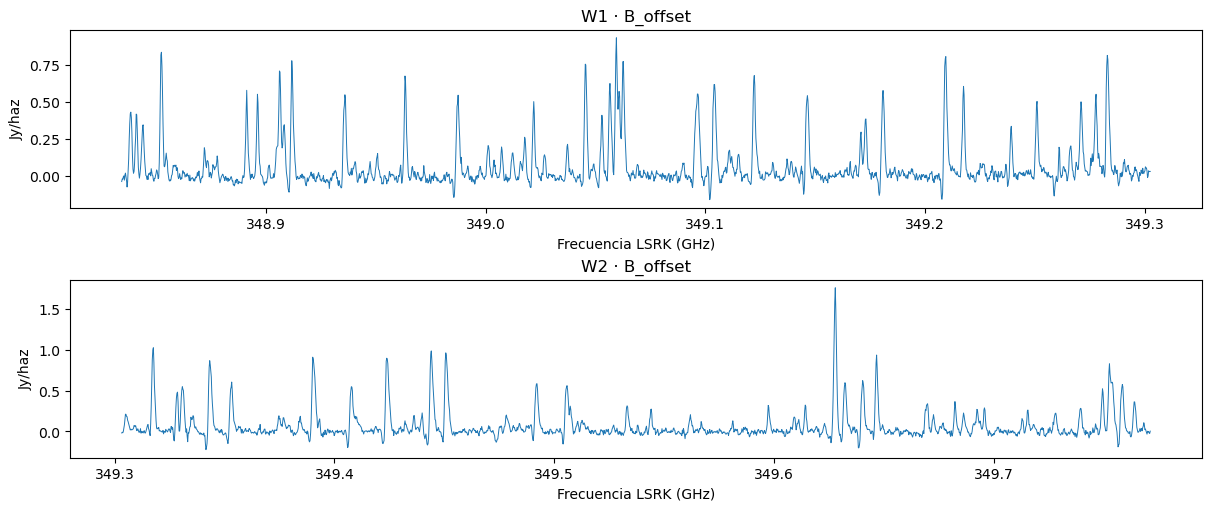

In [6]:
fig, axes = plt.subplots(2,1,figsize=(12,5),layout="constrained")
for i,ax in enumerate(axes,1):
    ax.plot(esp[i].frecuencia_LSRK_GHz, esp[i].B_offset_Jy_beam, lw=.7)
    ax.set(xlabel="Frecuencia LSRK (GHz)", ylabel="Jy/haz", title=f"W{i} · B_offset")
plt.show()

## Frecuencia y candidatos
Usamos velocidad radio: v = c (1 − ν_LSRK / ν_reposo). Para empezar puede explorarse v ≈ 2.7 km/s en B; debe comprobarse con varias líneas. Esta velocidad no se impone a A. La tolerancia depende de canal, perfil, error de catálogo y mezclas.

Selecciona una frecuencia **observada** de un pico. La función busca frecuencias en reposo cercanas después de corregir Doppler. Una coincidencia no identifica por sí misma una molécula.

--- Se encontraron 36 picos en la Ventana 1 (B_offset) ---
Frecuencia observada: 349.059536 GHz  |  Intensidad: 0.933 Jy/haz
Frecuencia observada: 348.852514 GHz  |  Intensidad: 0.835 Jy/haz
Frecuencia observada: 349.282915 GHz  |  Intensidad: 0.814 Jy/haz
Frecuencia observada: 349.209432 GHz  |  Intensidad: 0.806 Jy/haz
Frecuencia observada: 348.911838 GHz  |  Intensidad: 0.778 Jy/haz
Frecuencia observada: 349.062710 GHz  |  Intensidad: 0.773 Jy/haz
Frecuencia observada: 349.045377 GHz  |  Intensidad: 0.755 Jy/haz
Frecuencia observada: 348.906223 GHz  |  Intensidad: 0.709 Jy/haz
Frecuencia observada: 349.122278 GHz  |  Intensidad: 0.678 Jy/haz
Frecuencia observada: 348.963349 GHz  |  Intensidad: 0.675 Jy/haz
Frecuencia observada: 349.056607 GHz  |  Intensidad: 0.624 Jy/haz
Frecuencia observada: 349.103968 GHz  |  Intensidad: 0.617 Jy/haz
Frecuencia observada: 349.217488 GHz  |  Intensidad: 0.605 Jy/haz
Frecuencia observada: 348.891331 GHz  |  Intensidad: 0.578 Jy/haz
Frecuencia observ

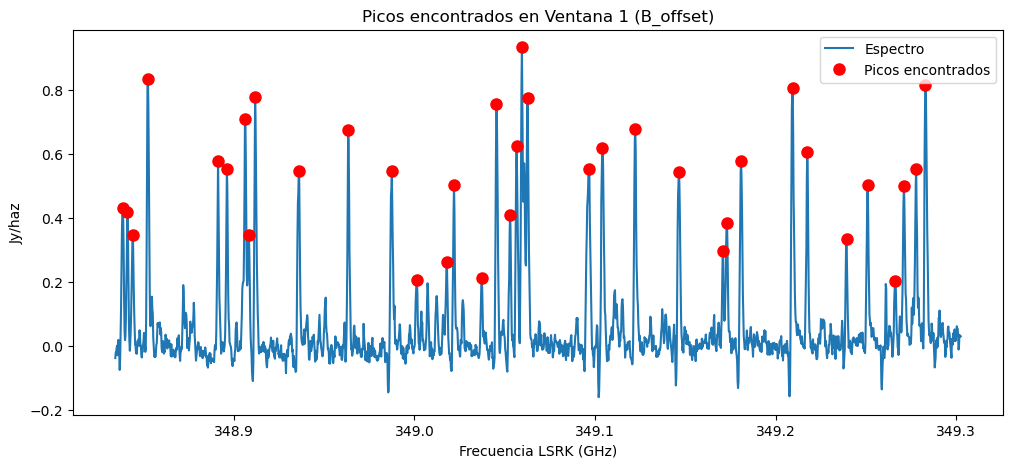

In [19]:
from scipy.signal import find_peaks

def buscar_picos(ventana, posicion="B_offset", altura_minima=0.15, prominencia=0.1):
    """
    Encuentra los picos en el espectro basándose en su altura y qué tanto 
    sobresalen del ruido a su alrededor (prominencia).
    """
    # Extraer los datos de la ventana y posición indicadas
    frecuencias = esp[ventana]["frecuencia_LSRK_GHz"].to_numpy()
    intensidades = esp[ventana][f"{posicion}_Jy_beam"].to_numpy()
    
    # Encontrar los picos
    indices, propiedades = find_peaks(intensidades, height=altura_minima, prominence=prominencia)
    
    print(f"--- Se encontraron {len(indices)} picos en la Ventana {ventana} ({posicion}) ---")
    
    # Imprimir los resultados ordenados por intensidad (de mayor a menor)
    # y guardar las frecuencias encontradas
    picos_encontrados = []
    for i in sorted(indices, key=lambda x: intensidades[x], reverse=True):
        frec = frecuencias[i]
        intensi = intensidades[i]
        picos_encontrados.append(frec)
        print(f"Frecuencia observada: {frec:.6f} GHz  |  Intensidad: {intensi:.3f} Jy/haz")
        
    return picos_encontrados

# Ejecutamos la función para la ventana 1 en B_offset
frecuencias_picos_w1 = buscar_picos(ventana=1, posicion="B_offset", altura_minima=0.2, prominencia=0.15)

# Visualización de los picos encontrados
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(esp[1]["frecuencia_LSRK_GHz"], esp[1]["B_offset_Jy_beam"], label="Espectro")
# Aumentar el tamaño de los marcadores y cambiar el color a rojo
ax.plot(frecuencias_picos_w1, esp[1].set_index("frecuencia_LSRK_GHz").loc[frecuencias_picos_w1]["B_offset_Jy_beam"], 'ro', markersize=8, label="Picos encontrados")
ax.set(xlabel="Frecuencia LSRK (GHz)", ylabel="Jy/haz", title="Picos encontrados en Ventana 1 (B_offset)")
ax.legend()

## Aplicando la corrección Doopler de 2.7 km/s

In [18]:
from IPython.display import display

C = 299792.458 # km/s

def candidatos(nu_observada_GHz, v_kms=2.7, tolerancia_MHz=1.0):
    nu_reposo_MHz = 1000*nu_observada_GHz/(1-v_kms/C)
    d = cat.assign(delta_MHz=cat.frecuencia_reposo_MHz-nu_reposo_MHz)
    return d[abs(d.delta_MHz)<=tolerancia_MHz].sort_values("delta_MHz")

# Iterar sobre los primeros 5 picos más intensos de la lista generada
for frec in frecuencias_picos_w1[:5]:
    print(f"\n--- Candidatos para el pico observado en {frec:.6f} GHz ---")
    
    # (Asumimos v_kms=2.7 y tolerancia de 1 MHz)
    df_candidatos = candidatos(nu_observada_GHz=frec, v_kms=2.7, tolerancia_MHz=1.0)
    
    if df_candidatos.empty:
        print("No se encontraron moléculas candidatas en el catálogo local con esta tolerancia.")
    else:
        # Filtramos columnas clave para facilitar la lectura en el cuaderno
        columnas_utiles = ["especie", "frecuencia_reposo_MHz", "delta_MHz", "E_superior_K", "tag_original"]
        display(df_candidatos[columnas_utiles])


--- Candidatos para el pico observado en 349.059536 GHz ---


,especie,frecuencia_reposo_MHz,delta_MHz,E_superior_K,tag_original
92,C2H5OH,349062.0450,-0.634939,993.981389,46524
93,C2H5OH,349062.0450,-0.634939,993.981389,46524
94,Glycine-I,349062.5309,-0.149039,490.309654,75511
95,CH3CHO,349062.5432,-0.136739,398.297284,44003



--- Candidatos para el pico observado en 348.852514 GHz ---


,especie,frecuencia_reposo_MHz,delta_MHz,E_superior_K,tag_original
10,CH3CHO,348855.5714,-0.084474,398.269222,44003



--- Candidatos para el pico observado en 349.282915 GHz ---


,especie,frecuencia_reposo_MHz,delta_MHz,E_superior_K,tag_original
170,CH3CN,349286.006,-0.054951,346.221552,41505



--- Candidatos para el pico observado en 349.209432 GHz ---


,especie,frecuencia_reposo_MHz,delta_MHz,E_superior_K,tag_original
149,CH3CN,349212.3109,-0.266289,424.702142,41505
150,CH3CN,349212.3109,-0.266289,424.702142,41505



--- Candidatos para el pico observado en 348.911838 GHz ---


,especie,frecuencia_reposo_MHz,delta_MHz,E_superior_K,tag_original
30,CH3OCHO,348915.0087,0.028691,294.595683,60003
31,C2H5CN,348915.3433,0.363291,787.050609,55502
32,CH3CHO,348915.6356,0.655591,1305.362655,44003


## Ruido y ajuste local
Selecciona al menos tres intervalos sin rasgos visibles, evita absorciones y bordes. No uses el RMS de toda la ventana, dominado por líneas. Registra tus intervalos. En canales correlacionados, la incertidumbre del área no sigue automáticamente √N.
El ajuste gaussiano es descriptivo: revisa residuos. Un perfil asimétrico o mezclado puede invalidarlo. El error formal no incluye calibración, opacidad, selección de baseline ni resolución instrumental.

In [ ]:
def ruido_empirico(ventana, intervalos_GHz, posicion="B_offset"):
    d=esp[ventana]; f=d.frecuencia_LSRK_GHz.to_numpy(); y=d[posicion+"_Jy_beam"].to_numpy()
    piezas=[]
    for lo,hi in intervalos_GHz:
        z=y[(f>=lo)&(f<=hi)]
        if len(z)<5: raise ValueError("Se requieren al menos 5 canales por intervalo")
        piezas.append(z-np.median(z))
    return np.std(np.concatenate(piezas),ddof=1)

def ajustar(ventana, nu_reposo_GHz, vmin, vmax, posicion="B_offset"):
    d=esp[ventana]; f=d.frecuencia_LSRK_GHz.to_numpy(); y=d[posicion+"_Jy_beam"].to_numpy()
    v=C*(1-f/nu_reposo_GHz); m=(v>=vmin)&(v<=vmax); x,z=v[m],y[m]
    if len(x)<9: raise ValueError("Usa una región con al menos 9 canales")
    def gauss(x,a,mu,sigma,b):return b+a*np.exp(-.5*((x-mu)/sigma)**2)
    base=np.median(z); amp=max(z)-base; mu=x[np.argmax(z)]
    par,cov=curve_fit(gauss,x,z,p0=[amp,mu,.5,base],bounds=([0,vmin,.1,-np.inf],[np.inf,vmax,3,np.inf]))
    a,mu,sd,b=par; residual=z-gauss(x,*par)
    fig,ax=plt.subplots(figsize=(7,3)); ax.step(x,z,where="mid",label="datos")
    xx=np.linspace(vmin,vmax,300);ax.plot(xx,gauss(xx,*par),label="gaussiana + constante")
    ax.plot(x,residual,label="residuos"); ax.set(xlabel="v radio LSRK (km/s)",ylabel="Jy/haz"); ax.legend();plt.show()
    return dict(v_centro=mu,FWHM=2.35482*sd,pico=a,baseline=b,area=a*sd*np.sqrt(2*np.pi),errores_formales=np.sqrt(np.diag(cov)),rms_residuo=np.std(residual,ddof=4))

ruido_empirico(1, [(inicio_GHz, fin_GHz), ...])
ajustar(ventana=1, nu_reposo_GHz=..., vmin=..., vmax=...)

## Cubo opcional y extracción verificable
Los índices son de Python, empiezan en cero. B_offset está en (x,y)=(54,46) en ambos recortes. El valor es Jy por haz en un píxel; sumar píxeles no da directamente Jy. No uses RESTFRQ de una ventana como frecuencia de todas las transiciones.
Para comparar W1/W2 espacialmente, ten en cuenta que los haces difieren. Para integrar emisión, conserva el eje de frecuencia y convierte Δν a Δv por transición.

In [ ]:
with fits.open(ROOT / "cubos/W1_IRAS16293.fits", memmap=True) as hd:
    cube=hd[0].data
    header=hd[0].header
    print(cube.shape, header["BUNIT"], header["SPECSYS"])
    extraido=cube[:,46,54].copy()
assert np.allclose(extraido,esp[1].B_offset_Jy_beam,rtol=1e-7,atol=1e-9)
print("Extracción B_offset verificada")

## Entrega
Rellena `evidencia_plantilla.csv`. Agrupa transiciones no resueltas en un único rasgo. Incluye frecuencias observadas y de reposo, errores, alternativas, mezclas y decisiones. Exporta figuras legibles; añade un README que permita repetir tus resultados. Declara uso de IA, catálogos y bibliografía. Para una conclusión insuficiente, explica qué medición adicional la resolvería.